In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Setup ----
import os
import shutil
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm

INPUT_DIR = "/content/drive/MyDrive/Crop Disease AI project/Member 01_IT25103233/Resized_Dataset"
OUTPUT_DIR = "/content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/Outputs"
EDA_DIR = "/content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/EDA"
LOCAL_SAVE_DIR = "/content/local_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(EDA_DIR, exist_ok=True)
os.makedirs(LOCAL_SAVE_DIR, exist_ok=True)

print("Exists:", os.path.exists(INPUT_DIR))
print("Contents of INPUT_DIR:", os.listdir(INPUT_DIR))

Exists: True
Contents of INPUT_DIR: ['Validation', 'Train']


In [3]:
# Combined histogram bins (shared across both splits)
combined_raw_hist = np.zeros(256, dtype=np.int64)
combined_norm_hist = np.zeros(50, dtype=np.int64)
norm_bin_edges = np.linspace(0, 1, 51)

In [4]:
# Process Train and Validation, one image at a time
for split in ["Train", "Validation"]:   # match exact names from the print above
    split_dir = os.path.join(INPUT_DIR, split)

    if not os.path.exists(split_dir):
        print(f"WARNING: {split_dir} does not exist — check folder name/path")
        continue

    image_paths = []
    labels = []
    for root, dirs, files in os.walk(split_dir):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                image_paths.append(os.path.join(root, f))
                labels.append(os.path.basename(root))

    N = len(image_paths)
    print(f"\n{split}: found {N} images")

    if N == 0:
        continue

    # On-disk array — writes each image directly to disk, RAM stays small
    memmap_path = os.path.join(LOCAL_SAVE_DIR, f"{split.lower()}_normalized_images.npy")
    output_array = np.lib.format.open_memmap(
        memmap_path, mode="w+", dtype="float32", shape=(N, 224, 224, 3)
    )

    for i, path in enumerate(tqdm(image_paths, desc=f"Processing {split}")):
        img = np.array(Image.open(path).convert("RGB"))   # one image only

        counts, _ = np.histogram(img, bins=256, range=(0, 256))
        combined_raw_hist += counts

        normalized = img.astype("float32") / 255.0
        output_array[i] = normalized

        counts, _ = np.histogram(normalized, bins=norm_bin_edges)
        combined_norm_hist += counts

    output_array.flush()
    print(f"{split}: saved normalized array locally to {memmap_path}")

    # Save labels and filepaths
    np.save(os.path.join(LOCAL_SAVE_DIR, f"{split.lower()}_labels.npy"), np.array(labels))
    np.save(os.path.join(LOCAL_SAVE_DIR, f"{split.lower()}_filepaths.npy"), np.array(image_paths))

    # ---- Copy all this split's files to Drive ----
    for fname in [f"{split.lower()}_normalized_images.npy", f"{split.lower()}_labels.npy", f"{split.lower()}_filepaths.npy"]:
        print(f"Copying {fname} to Drive...")
        shutil.copy(os.path.join(LOCAL_SAVE_DIR, fname), os.path.join(OUTPUT_DIR, fname))
        print(f"Done: {fname}")

    print(f"Saved {split} outputs to {OUTPUT_DIR}")

    # Release the memmap reference for this split before moving to the next
    del output_array


Train: found 11662 images


Processing Train: 100%|██████████| 11662/11662 [1:49:26<00:00,  1.78it/s]


Train: saved normalized array locally to /content/local_outputs/train_normalized_images.npy
Copying train_normalized_images.npy to Drive...
Done: train_normalized_images.npy
Copying train_labels.npy to Drive...
Done: train_labels.npy
Copying train_filepaths.npy to Drive...
Done: train_filepaths.npy
Saved Train outputs to /content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/Outputs

Validation: found 2012 images


Processing Validation: 100%|██████████| 2012/2012 [16:12<00:00,  2.07it/s]


Validation: saved normalized array locally to /content/local_outputs/validation_normalized_images.npy
Copying validation_normalized_images.npy to Drive...
Done: validation_normalized_images.npy
Copying validation_labels.npy to Drive...
Done: validation_labels.npy
Copying validation_filepaths.npy to Drive...
Done: validation_filepaths.npy
Saved Validation outputs to /content/drive/MyDrive/Crop Disease AI project/Member 02_IT25103229/Outputs


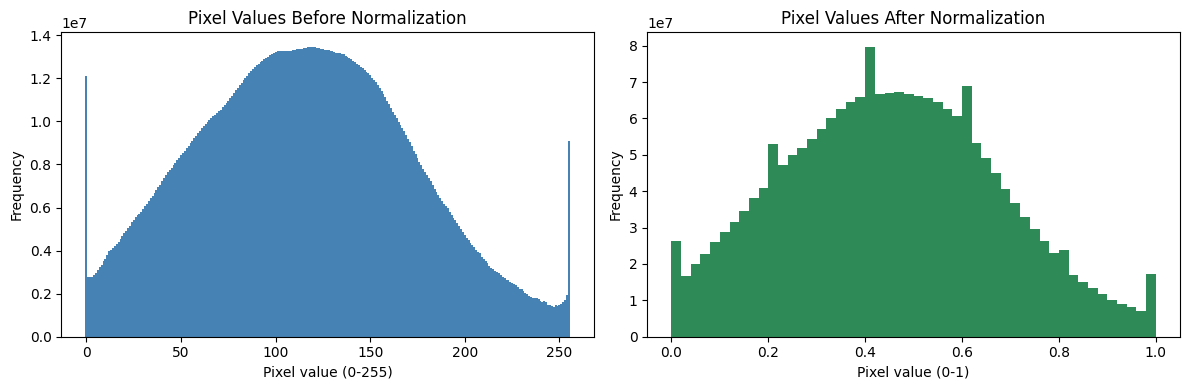


All done. Train and Validation saved to Outputs, histogram saved to EDA.


In [5]:
# EDA: plot the combined histograms (built incrementally, no big arrays needed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

raw_bin_centers = np.arange(256)
norm_bin_centers = (norm_bin_edges[:-1] + norm_bin_edges[1:]) / 2

axes[0].bar(raw_bin_centers, combined_raw_hist, color="steelblue", width=1.0)
axes[0].set_title("Pixel Values Before Normalization")
axes[0].set_xlabel("Pixel value (0-255)")
axes[0].set_ylabel("Frequency")

axes[1].bar(norm_bin_centers, combined_norm_hist, color="seagreen", width=norm_bin_edges[1]-norm_bin_edges[0])
axes[1].set_title("Pixel Values After Normalization")
axes[1].set_xlabel("Pixel value (0-1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(os.path.join(EDA_DIR, "pixel_normalization_histogram.png"))
plt.show()

print("\nAll done. Train and Validation saved to Outputs, histogram saved to EDA.")